# Reducing Gemini GMOS long-slit spectra with easyspec: spectral and spatial dithers

In this tutorial we reduce a GMOS-S long-slit dataset of the star **J2145+0031** (grating B600, 1.0 arcsec slit, 2x2 binning) and combine all its exposures into a single flux-calibrated spectrum. The data are the "dithered" tutorial package of the Gemini DRAGONS pipeline.

The target was observed with a typical GMOS strategy:

- **two central wavelengths** (515 nm and 530 nm, *spectral dithers*): the three CCDs of GMOS are separated by gaps of ~3 arcsec, so each central wavelength has two wavelength intervals without data. With two central wavelengths, the gaps fall at different wavelengths and the combined spectrum has no gaps;
- **two positions along the slit** for each central wavelength (*spatial dithers*): bad pixels, bad columns and residuals of the sky subtraction fall at different places of the spectrum in each exposure.

That is 4 exposures of the target, each one in its own directory. The flux standard star **LTT2415** was observed only with the central wavelength of 515 nm, in another night, with its own flat field and arc lamp.

The plan:

1. convert the raw GMOS files into images that easyspec can read (`gmos.convert()`);
2. reduce the images with `cleaning()`: once for each central wavelength (the two dithers together) and once for the standard star;
3. extract the standard star spectrum and compute the sensitivity function;
4. extract and calibrate (wavelength, extinction, flux) the 4 spectra of the target;
5. stack the 4 spectra with `analysis.stack_calib_spectra()`.

Steps 2 and 4 are written as functions, so that the same reduction is applied to all exposures. Their argument `plot` controls the plots: with `plot=False` nothing is plotted; with `plot=True` only the main plots are shown.


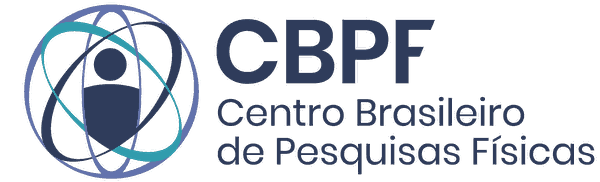

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from easyspec.gemini import gmos
from easyspec.cleaning import cleaning
from easyspec.extraction import extraction
from easyspec.analysis import analysis

## Settings

All the paths and the information about the target are defined here:

In [2]:
raw_data = Path("./Gemini/gmosls_tutorial_datapkg-dithered-v1/gmosls_tutorial/playdata/example1")   # Raw GMOS files
converted_data = Path("./gmos_converted")     # Output of gmos.convert()
reduced_data = Path("./gmos_reduced")         # Master files of each reduction (output of cleaning())
output_directory = Path("./Gemini_results")   # Calibrated 1D spectra
reduced_data.mkdir(exist_ok=True)
output_directory.mkdir(exist_ok=True)

target_name = "J2145+0031"
standard_star_name = "LTT2415"

# The two setups (central wavelengths) of the target, and the two dither positions of each one:
setups = ["longslit_B600_515nm_1.0arcsec_2x2", "longslit_B600_530nm_1.0arcsec_2x2"]
dithers = ["dither1", "dither2"]

# The standard star was observed only with the central wavelength of 515 nm:
standard_star_setup = "longslit_B600_515nm_1.0arcsec_2x2"

saturation_level = 107000   # Electrons (keyword SATURATE of the converted files)
reddening = 0.072           # Galactic E(B-V) in the direction of the target (IRSA dust service)
observatory = "ctio"        # Extinction curve: Gemini South is on Cerro Pachon, next to CTIO

## Step 1. Converting the raw GMOS data

A raw GMOS frame has one fits extension per amplifier (12 for the Hamamatsu CCDs). `gmos.convert()` subtracts the overscan of each amplifier, converts it to electrons with its own gain, assembles the three CCDs into a single image (the gaps between the CCDs and the bad pixels are set to NaN) and sorts the frames into one directory per setup, with the subdirectories that `cleaning()` expects. The spatial dithers go to different directories (`target_J2145+0031_dither1`, `target_J2145+0031_dither2`).

This step only needs to be run once. If you already have the directory `gmos_converted`, you can skip it.

In [3]:
setup_paths = gmos.convert(raw_data,                 # Directory with the raw files (.fits or .fits.bz2)
                                  converted_data,           # Output directory
                                  bad_pixel_mask="auto",    # Use the BPM file found among the raw files
                                  overscan="row",           # Overscan level subtracted row by row
                                  units="electron",         # Each amplifier is multiplied by its own gain
                                  common_rows=True,         # Cut all frames to the rows of the standard star
                                  blue_left=True,           # Wavelength increasing along x
                                  dither_tolerance=0.5,     # Arcsec: exposures closer than this are the same dither position
                                  overwrite=True)

51 frames converted into 2 setup(s):

  longslit_B600_515nm_1.0arcsec_2x2   (image shape 512x3134, detector rows 1625-2648)
      bias/                                  20 frame(s)
      flat/                                   1 frame(s)
      flat_standard_star/                     1 frame(s)
      lamp/                                   1 frame(s)
      lamp_standard_star/                     1 frame(s)
      standard_star_LTT2415/                  1 frame(s)   exposure 60 s, airmass 1.16, offset along the slit +1.2 arcsec
      target_J2145+0031_dither1/              1 frame(s)   exposure 1050 s, airmass 1.21, offset along the slit -0.4 arcsec
      target_J2145+0031_dither2/              1 frame(s)   exposure 1050 s, airmass 1.25, offset along the slit +14.6 arcsec
      note: flat_standard_star/ and lamp_standard_star/ were taken with the standard star, in another night: use them (instead of flat/ and lamp/)
            if you need the calibrations closest to the standard star

  

In the summary above, notice that the setup of 515 nm has the directories `flat_standard_star` and `lamp_standard_star`. They contain the flat field and the arc lamp taken together with the standard star, two months before the target. GMOS flexes with the position of the telescope, so the spectra (and the lamp lines) move by a few pixels on the detector from one pointing to the other: each object must be calibrated with the flat and the lamp taken with it.

## Step 2. Image reduction

**Why is the standard star reduced separately?** `cleaning()` combines all the flats of a reduction into one master flat, and all the lamps into one master lamp. If the standard star were reduced together with the target, its flat and lamp would be mixed with those of the target. Reducing it separately is also the simplest option: it is just one more call of the same function, with the directories of its own flat and lamp.

The function below reduces the frames of one setup, from the raw images to the master files with their variance and data quality mask (as in the main spectroscopy tutorial).

**The flat field.** The three CCDs of GMOS do not have the same sensitivity: at these wavelengths, the red CCD is ~16% less sensitive than the middle one, so every spectrum (flat, lamp, standard star and target) has a step at the gaps. With `keep_ccd_steps=True`, `norm_master_flat()` measures these steps on the flat and builds the model of the lamp spectrum (here with a running median) continuous across the gaps. The steps then stay in the normalized flat and are corrected by `flatten()`: after the flat field, the three CCDs are on the same scale. This is needed because the sensitivity function of the standard star is smooth (it cannot follow a step), and because the spectra of 530 nm have their gaps at other wavelengths than the standard star (observed at 515 nm). The argument `object_type` is `"target"` or `"standard_star"`. The master files are written by easyspec in the working directory, so at the end they are moved to `output_folder`.

In [4]:
def reduce_frames(setup, flat_folder, lamp_folder, object_type, object_folders, output_folder, plot=False):
    c = cleaning()
    setup_folder = converted_data/setup

    # Read the frames
    if object_type == "target":
        raw = c.data_paths(bias=setup_folder/"bias", flats=setup_folder/flat_folder, lamp=setup_folder/lamp_folder,
                           targets=object_folders)
    else:
        raw = c.data_paths(bias=setup_folder/"bias", flats=setup_folder/flat_folder, lamp=setup_folder/lamp_folder,
                           standard_star=object_folders)

    # Bias (the overscan was already subtracted by gmos.convert(), so the images are not trimmed)
    master_bias = c.master("bias", raw, method="median", plot=False)
    debiased = c.debias(raw, master_bias)

    # Flat field. keep_ccd_steps=True keeps the sensitivity steps between the three CCDs in the normalized flat (see the text above)
    master_flat = c.master("flat", debiased, method="median", plot=False)
    # The columns of the CCD gaps are in the header of the converted files (and of master_flat.fits, written by master())
    norm_flat = c.norm_master_flat(master_flat, method="median_filter", smooth_window=51, keep_ccd_steps=True,
                                   ccd_gaps=gmos.ccd_gaps("master_flat.fits"), max_flat_noise=0.015, plots=True)
    flattened = c.flatten(debiased, norm_flat)

    # The converted images are already in electrons (GAIN = 1); cosmic rays; variance and data quality mask of every pixel
    electrons = c.gain_correct(flattened, gain_header_entry="GAIN", verbose=False)
    cleaned = c.remove_cosmic_rays(electrons, readnoise_header_entry="RDNOISE", saturation_level=saturation_level, verbose=False)
    variance, mask = c.compute_variance(cleaned, verbose=False)

    # Master lamp and master target(s) or standard star (one master per directory: one per dither)
    c.master("lamp", cleaned, method="median", plot=False)
    c.master(object_type, cleaned, method="median", exposure_header_entry="EXPTIME", airmass_header_entry="AIRMASS",
             variance=variance, mask=mask, plot=plot)

    # master() writes the master files in the working directory: move them to the output folder
    output_folder.mkdir(parents=True, exist_ok=True)
    Path("master_lamp.fits").replace(output_folder/"master_lamp.fits")
    if object_type == "target":
        for folder in object_folders:
            Path(f"master_target_{folder.name}.fits").replace(output_folder/f"master_target_{folder.name}.fits")
    else:
        Path("master_standard_star.fits").replace(output_folder/"master_standard_star.fits")
    for name in ("master_bias.fits", "master_flat.fits", "norm_master_flat.fits"):
        Path(name).replace(output_folder/name)

Now we reduce the target, one setup (central wavelength) at a time. The two dithers of each setup are reduced together, with the same bias, flat and lamp, but each one gets its own master file:

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:660: UserWarning: The master flat was built from a single frame, so its variance cannot be estimated from the data. It will be treated as noiseless, which underestimates the final uncertainties.
  warnings.warn(f"The {label} was built from a single frame, so its variance cannot be estimated from the data. "
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:990: RuntimeWarning: All-NaN slice encountered
  yvals = np.nanmedian(relative_rows, axis=0) * mean_level  # Column profile, in the original units
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:991: RuntimeWarning: All-NaN slice encountered
  robust_std = 1.4826 * np.nanmedian(np.abs(relative_rows - np.nanmedian(relative_rows, axis=0)), axis=0) * mean_level
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1161: UserWarning: 'max_flat_noise' was given, but the variance of

Relative sensitivity of the CCDs (from left to right, measured on the flat): 1.016, 1.000, 0.841
Normalized master flat: 512/512 illuminated rows; median = 0.9961; robust scatter = 0.0292; 118716 pixels set to 1 (low signal).
112 bad columns identified (excluded from the model, corrected by the flat).


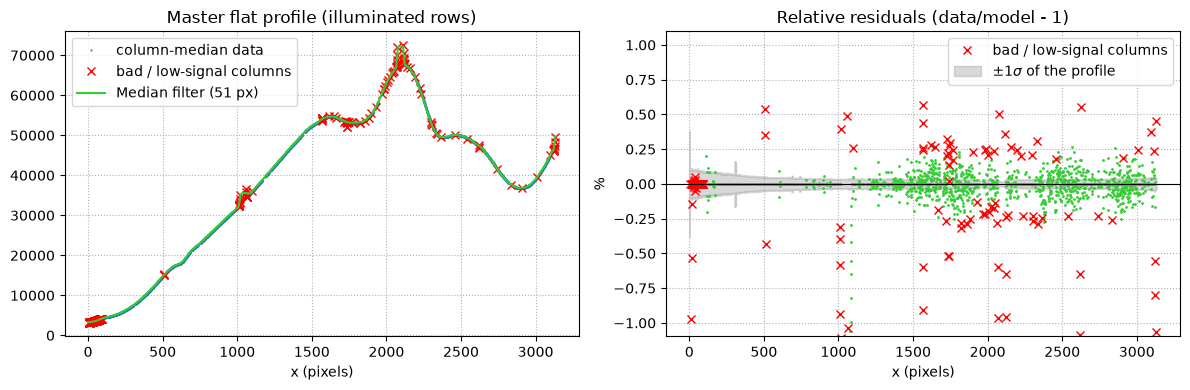

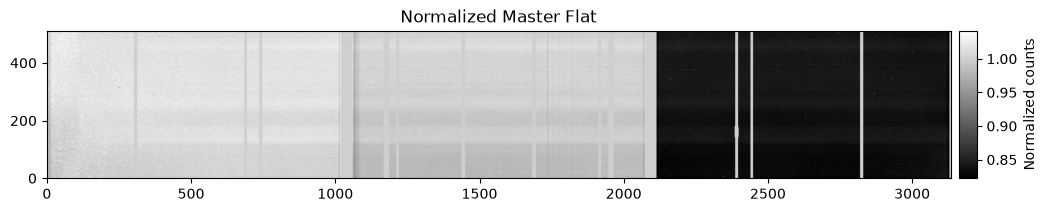

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1758: UserWarning: The following ingredients were not available, so their contribution to the variance was neglected: variance of the normalized flat. The uncertainties may be underestimated.
  warnings.warn("The following ingredients were not available, so their contribution to the variance was neglected: "
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:660: UserWarning: The master lamp was built from a single frame, so its variance cannot be estimated from the data. It will be treated as noiseless, which underestimates the final uncertainties.
  warnings.warn(f"The {label} was built from a single frame, so its variance cannot be estimated from the data. "


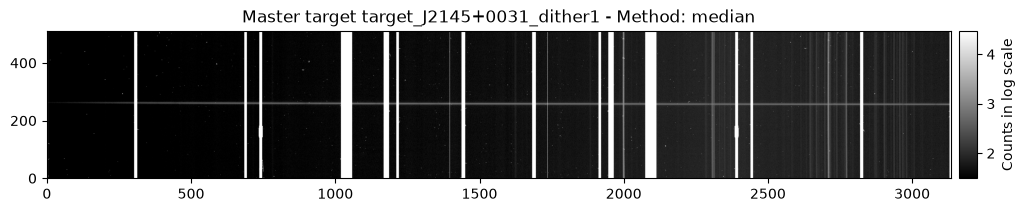

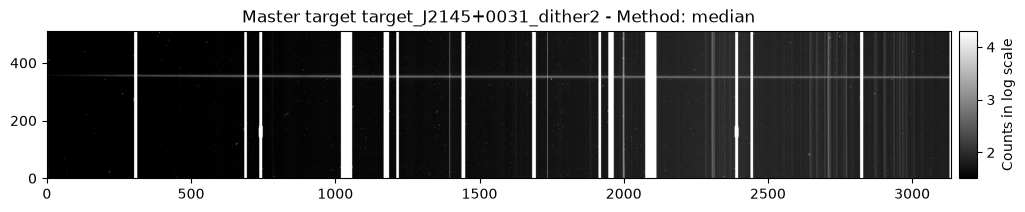

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:660: UserWarning: The master flat was built from a single frame, so its variance cannot be estimated from the data. It will be treated as noiseless, which underestimates the final uncertainties.
  warnings.warn(f"The {label} was built from a single frame, so its variance cannot be estimated from the data. "
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:990: RuntimeWarning: All-NaN slice encountered
  yvals = np.nanmedian(relative_rows, axis=0) * mean_level  # Column profile, in the original units
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:991: RuntimeWarning: All-NaN slice encountered
  robust_std = 1.4826 * np.nanmedian(np.abs(relative_rows - np.nanmedian(relative_rows, axis=0)), axis=0) * mean_level


Relative sensitivity of the CCDs (from left to right, measured on the flat): 0.976, 1.000, 0.846
Normalized master flat: 512/512 illuminated rows; median = 0.9735; robust scatter = 0.0389; 118716 pixels set to 1 (low signal).
104 bad columns identified (excluded from the model, corrected by the flat).


/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1161: UserWarning: 'max_flat_noise' was given, but the variance of the master flat is not available, so it was ignored.
  warnings.warn("'max_flat_noise' was given, but the variance of the master flat is not available, so it was ignored.")
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1180: UserWarning: The variance of the master flat is not available, so the variance of the normalized flat will not be computed.
  warnings.warn("The variance of the master flat is not available, so the variance of the normalized flat will not be computed.")


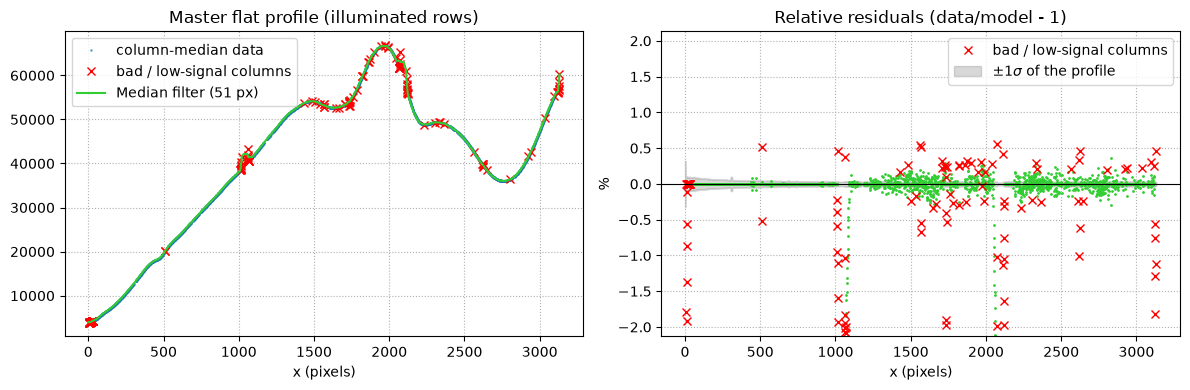

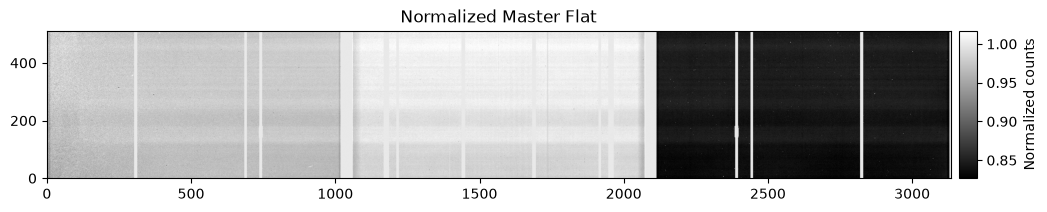

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1758: UserWarning: The following ingredients were not available, so their contribution to the variance was neglected: variance of the normalized flat. The uncertainties may be underestimated.
  warnings.warn("The following ingredients were not available, so their contribution to the variance was neglected: "
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:660: UserWarning: The master lamp was built from a single frame, so its variance cannot be estimated from the data. It will be treated as noiseless, which underestimates the final uncertainties.
  warnings.warn(f"The {label} was built from a single frame, so its variance cannot be estimated from the data. "


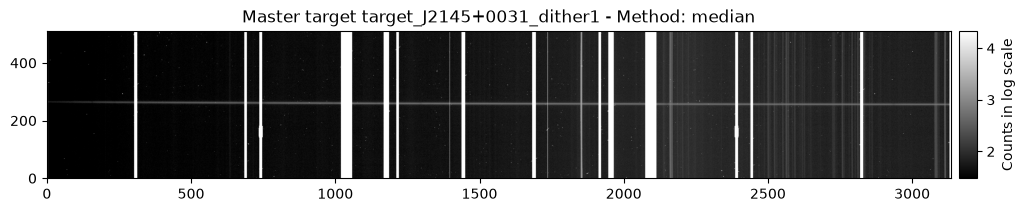

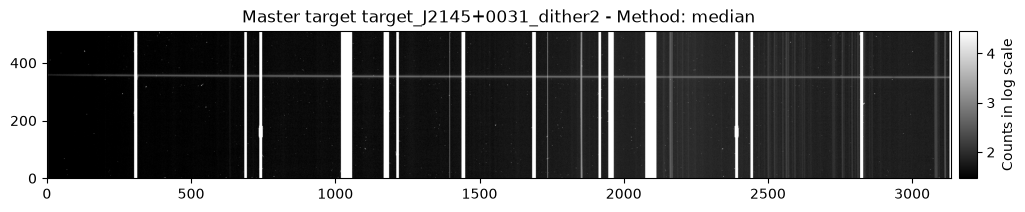

In [5]:
for setup in setups:
    target_folders = [converted_data/setup/f"target_{target_name}_dither1",
                      converted_data/setup/f"target_{target_name}_dither2"]
    reduce_frames(setup, flat_folder="flat", lamp_folder="lamp", object_type="target", object_folders=target_folders,
                  output_folder=reduced_data/setup, plot=True)

And the standard star, with its own flat field and lamp:

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:660: UserWarning: The master flat was built from a single frame, so its variance cannot be estimated from the data. It will be treated as noiseless, which underestimates the final uncertainties.
  warnings.warn(f"The {label} was built from a single frame, so its variance cannot be estimated from the data. "
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:990: RuntimeWarning: All-NaN slice encountered
  yvals = np.nanmedian(relative_rows, axis=0) * mean_level  # Column profile, in the original units
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:991: RuntimeWarning: All-NaN slice encountered
  robust_std = 1.4826 * np.nanmedian(np.abs(relative_rows - np.nanmedian(relative_rows, axis=0)), axis=0) * mean_level
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1161: UserWarning: 'max_flat_noise' was given, but the variance of

Relative sensitivity of the CCDs (from left to right, measured on the flat): 1.016, 1.000, 0.839
Normalized master flat: 512/512 illuminated rows; median = 0.9960; robust scatter = 0.0311; 118716 pixels set to 1 (low signal).
103 bad columns identified (excluded from the model, corrected by the flat).


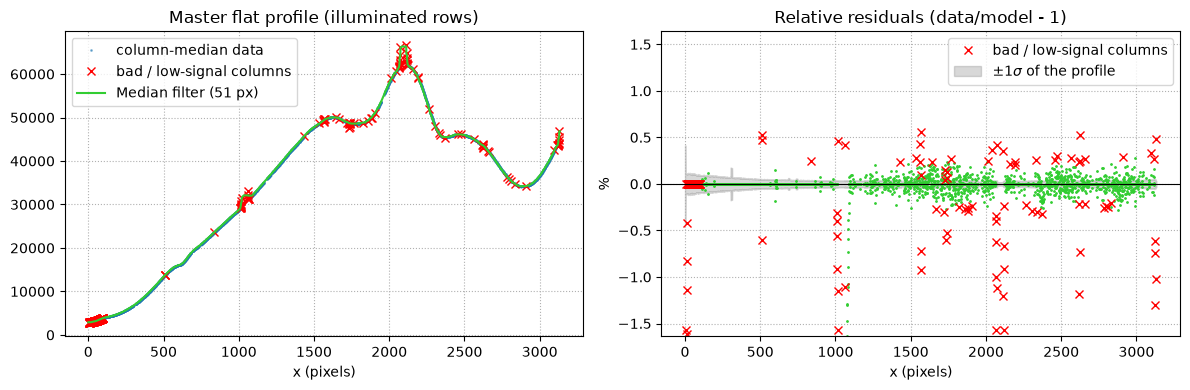

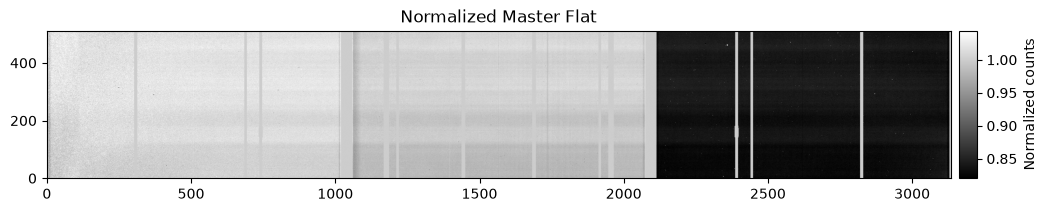

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:1758: UserWarning: The following ingredients were not available, so their contribution to the variance was neglected: variance of the normalized flat. The uncertainties may be underestimated.
  warnings.warn("The following ingredients were not available, so their contribution to the variance was neglected: "
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:660: UserWarning: The master lamp was built from a single frame, so its variance cannot be estimated from the data. It will be treated as noiseless, which underestimates the final uncertainties.
  warnings.warn(f"The {label} was built from a single frame, so its variance cannot be estimated from the data. "


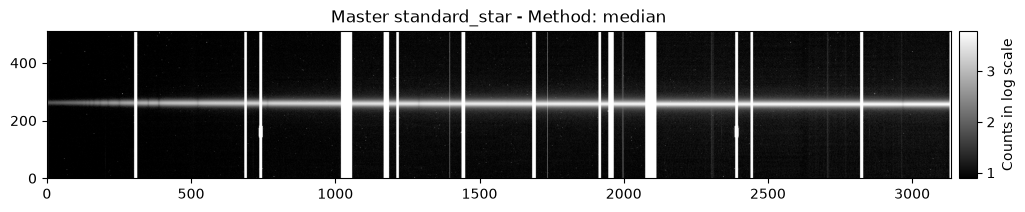

In [6]:
standard_star_folders = [converted_data/standard_star_setup/f"standard_star_{standard_star_name}"]
reduce_frames(standard_star_setup, flat_folder="flat_standard_star", lamp_folder="lamp_standard_star", object_type="standard_star",
              object_folders=standard_star_folders, output_folder=reduced_data/"standard_star", plot=True)

The directory `gmos_reduced` now contains one subdirectory per reduction, each with its master lamp and its master target(s) or master standard star.

## Step 3. The standard star and the sensitivity function

The extraction follows the main spectroscopy tutorial: tracing, optimal extraction, wavelength calibration with the CuAr lamp, and correction for the atmospheric extinction. The sensitivity function is computed only once, from the standard star, and then applied to all the spectra of the target.

A few GMOS details:

- the arc lamp of GMOS is CuAr: we use the line list of the Gemini pipeline, `gmos.CUAR_LINE_LIST`;
- `gmos.wavelength_range()` reads, from the header of the lamp, the approximate wavelengths at the first and at the last column (computed from the grating and the central wavelength);
- the lamp lines are ~5.5 pixels wide (1 arcsec slit, 2x2 binning), so we accept identifications with an RMS up to 0.4 pixels;
- the spectrum covers ~3100 A on three CCDs, so the wavelength solution needs a polynomial of order 4.

`import_data()` always needs a target image. Here the standard star is given both as the target and as the standard star (only the latter is used).

In [7]:
def standard_star_sensitivity(plot=False):
    e = extraction()
    standard_star_file = reduced_data/"standard_star"/"master_standard_star.fits"
    lamp_file = reduced_data/"standard_star"/"master_lamp.fits"
    _, std_data = e.import_data(standard_star_file, standard_star_name, std_star_spec_file=standard_star_file, plot=False)

    # Trace and optimal extraction (the lamp is extracted along the same trace)
    std_trace = e.tracing(std_data, method="profile", poly_order=2, xlims=[0, 3000], y_pixel_range=15,
                          main_plot=plot, plot_residuals=False)
    spec_std_list, lamp_spec_list_std, _ = e.extracting(std_data, std_trace, data_type="std_star", master_lamp_data=lamp_file,
                                                         trace_half_width=7, shift_y_pixels=21, extraction_weights="optimal",
                                                         diagnostic_plots=False, spec_plots=False)

    # Wavelength calibration
    lamp_peaks, lamp_wavelengths = e.identify_lamp_lines(lamp_spec_list_std, lamps=gmos.CUAR_LINE_LIST,
                                                         wavelength_range=gmos.wavelength_range(lamp_file),
                                                         medium="air", max_rms_pixels=0.4, plots=False)
    wavelengths_std, _ = e.wavelength_calibration(lamp_peaks, lamp_wavelengths, data_type="std_star", poly_order=4,
                                                  diagnostic_plots=False)

    # Atmospheric extinction and sensitivity function
    spec_atm_corrected_std = e.extinction_correction(spec_std_list, wavelengths_std, observatory=observatory, data_type="std_star",
                                                     plots=False)
    sensitivity_function = e.std_star_normalization(spec_atm_corrected_std, wavelengths_std, std_star_dataset="ctionewcal",
                                                    std_star_archive_file="l2415.dat", mask_telluric=True, clip_sigma=3.5,
                                                    plots=plot)
    # The extinction-corrected spectrum of the standard star and its wavelengths are also returned: they are used for the telluric correction
    return sensitivity_function, spec_atm_corrected_std, wavelengths_std

Returning both target and std star images...
Spectrum 0: y = 258.33 at x = 1567; 77 of 97 bins used (x = 15-2988); residual RMS = 0.049 px; spatial FWHM = 8.78 px


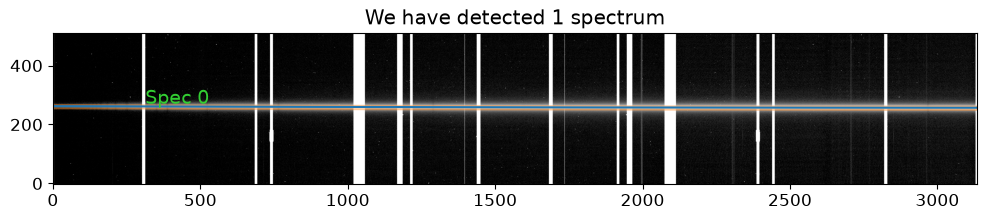

Spectrum 0: median S/N per pixel = 169.8; profile: empirical (FWHM = 8.0 px, order 3 along x); 3 outlier pixel(s) rejected; variance relative to a simple sum = 0.99.
The built-in line lists adopted here (HgI, NeI, ArI, HeI, CuI, CdI, ZnI, KrI, XeI, FeI, ThAr) were taken from PypeIt, which compiled them from NIST and instrument calibrations. Please cite PypeIt and NIST if you use them.
Lamp spectrum 0: 125 lines detected, 70 identified (RMS = 0.228 A = 0.227 px); lambda = 3595.4 to 6737.4 A.
Spectrum 0: 70 lines used, 0 rejected; RMS = 0.2285 A (0.227 px); dispersion = 1.0055 A/px; lambda = 3595.1-6737.3 A.
Please cite the work where this extinction curve was measured:
The CTIO extinction curve was originally distributed with IRAF and comes from the work of Stone & Baldwin (1983 MN 204, 347) plus Baldwin & Stone (1984 MN 206, 241). The first of these papers lists the points from 3200-8370A while the second extended the flux calibration from 6056 to 10870A but the derived extinction curv

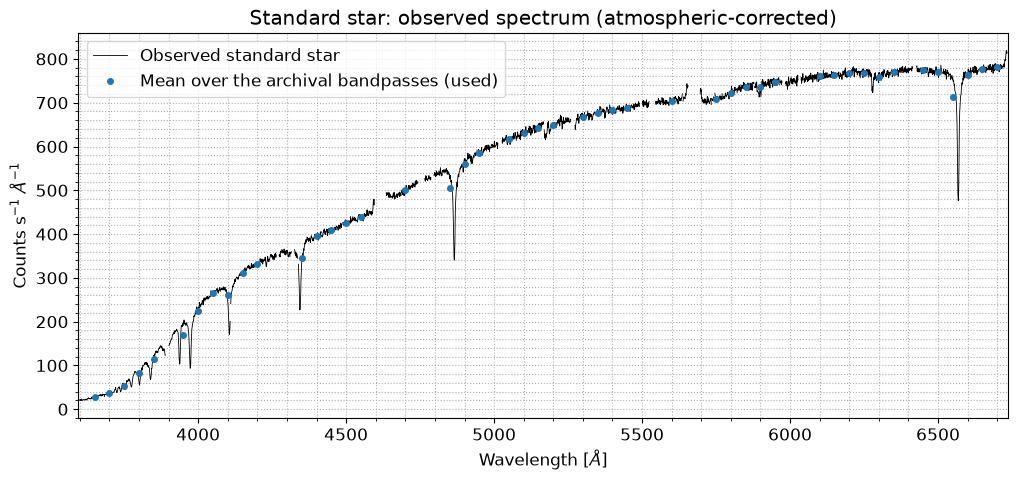

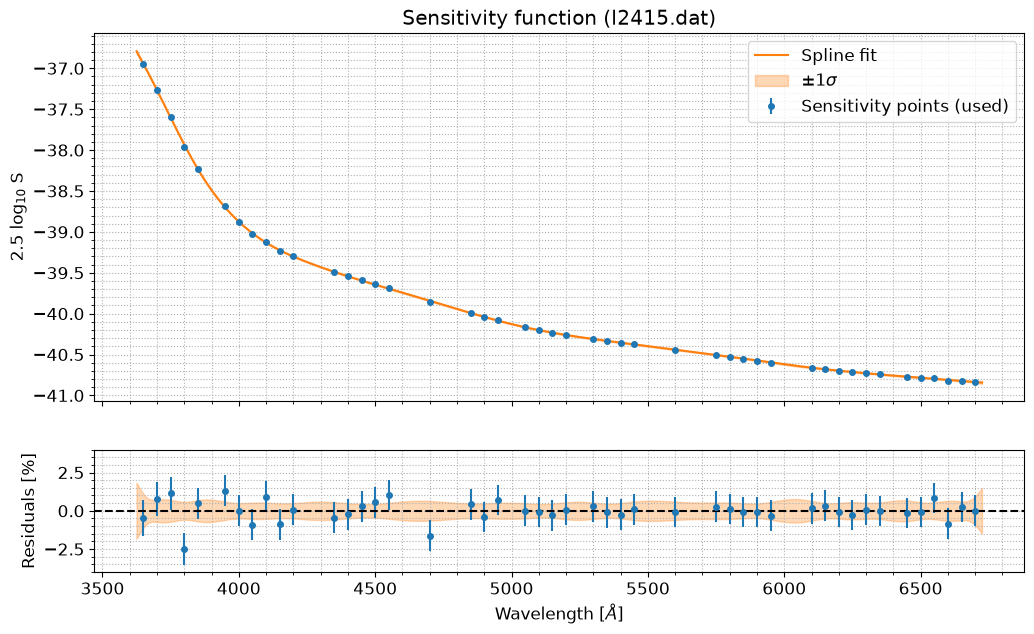

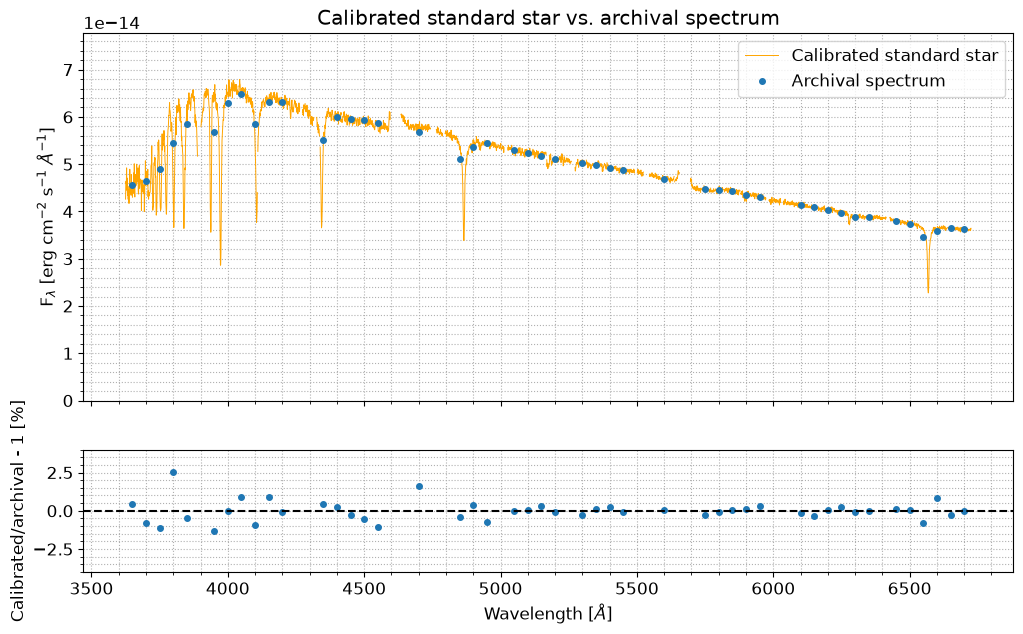

Please cite the reference of the archival spectrum:
Fluxes at 50A steps in the blue range 3300-7550A for the tertiary standards of Baldwin and Stone derived from the revised calibration of Hamuy et al., 1992, PASP, 104, 533. This dataset also contains the fluxes of the tertiaries in the red (6050-10000A) at 50A steps as published in Hamuy et al. 1994, PASP, 106, 566. The combined fluxes are obtained by gray shifting the blue fluxes to match the red fluxes in the overlap region of 6500A-7500A and averaging the red and blue fluxes in the overlap. The separate red and blue fluxes may be selected by following the star name with 'red' or 'blue'; i.e. cd32blue.dat.


In [8]:
sensitivity_function, spec_atm_corrected_std, wavelengths_std = standard_star_sensitivity(plot=True)

## Step 4. Extracting and calibrating the 4 spectra of the target

The function below extracts one exposure (one dither of one setup), calibrates it in wavelength and flux (with the master lamp of its own setup) and corrects it for the telluric absorption. The telluric transmission is measured on the spectrum of the standard star and scaled to the airmass of each exposure. In the range of these spectra (3625-6725 A), only the weak O2 gamma band (~6280 A) is present: the strong O2 B (~6870 A) and A (~7600 A) bands are redder.

Each spectrum is saved in `output_directory` with a different name, e.g. `J2145+0031_longslit_B600_515nm_1.0arcsec_2x2_dither1_spec_0.dat` (flux calibrated) and `..._spec_0_telluric.dat` (also corrected for the telluric absorption). The function returns the name of the latter.

The pixels of the CCD gaps are NaN in the extracted spectra. They are left out of the flux calibration and of the stacking.

In [9]:
def calibrate_dither(setup, dither, sensitivity_function, spec_atm_corrected_std, wavelengths_std, plot=False):
    e = extraction()
    target_file = reduced_data/setup/f"master_target_target_{target_name}_{dither}.fits"
    lamp_file = reduced_data/setup/"master_lamp.fits"
    standard_star_file = reduced_data/"standard_star"/"master_standard_star.fits"
    spectrum_name = f"{target_name}_{setup}_{dither}"
    # The standard star image is also given, so that its airmass is known (needed by the telluric correction)
    target_data, _ = e.import_data(target_file, spectrum_name, std_star_spec_file=standard_star_file, plot=False)

    # Trace and optimal extraction
    trace = e.tracing(target_data, method="profile", poly_order=2, xlims=[0, 3000], y_pixel_range=10, distance=5,
                      peak_height=None, detection_sigma=3.0, clip_sigma=3.0, main_plot=plot, plot_residuals=False)
    spec_list, lamp_spec_list, _ = e.extracting(target_data, trace, data_type="target", master_lamp_data=lamp_file,
                                                trace_half_width=10, shift_y_pixels=30, extraction_weights="optimal",
                                                diagnostic_plots=False, spec_plots=False)

    # Wavelength calibration
    lamp_peaks, lamp_wavelengths = e.identify_lamp_lines(lamp_spec_list, lamps=gmos.CUAR_LINE_LIST,
                                                         wavelength_range=gmos.wavelength_range(lamp_file),
                                                         medium="air", max_rms_pixels=0.4, plots=False)
    wavelengths_list, _ = e.wavelength_calibration(lamp_peaks, lamp_wavelengths, data_type="target", poly_order=4,
                                                   diagnostic_plots=False)

    # Atmospheric extinction and flux calibration (the spectrum is saved in output_directory)
    spec_atm_corrected_list = e.extinction_correction(spec_list, wavelengths_list, observatory=observatory, data_type="target",
                                                      plots=False)
    wavelengths_sliced, calibrated_flux = e.target_flux_calibration(wavelengths_list, spec_atm_corrected_list, sensitivity_function,
                                                                    reddening=reddening, Rv=3.1, wavelength_cuts=None,
                                                                    output_directory=output_directory, save_spec=True,
                                                                    file_format="dat", plot=False)

    # Telluric correction, with the transmission measured on the standard star and scaled to the airmass of this exposure
    # (the corrected spectrum is saved as <spectrum_name>_spec_0_telluric.dat)
    e.telluric_correction(wavelengths_sliced, calibrated_flux, spec_atm_corrected_std, wavelengths_std, beta=0.55, fit_bands=False,
                          output_directory=output_directory, save_spec=True, file_format="dat", plots=plot)
    return output_directory/f"{spectrum_name}_spec_0_telluric.dat"

Now we run it for the 4 exposures:

Returning both target and std star images...
Spectrum 0: y = 258.18 at x = 1567; 75 of 97 bins used (x = 15-2988); residual RMS = 0.041 px; spatial FWHM = 3.83 px


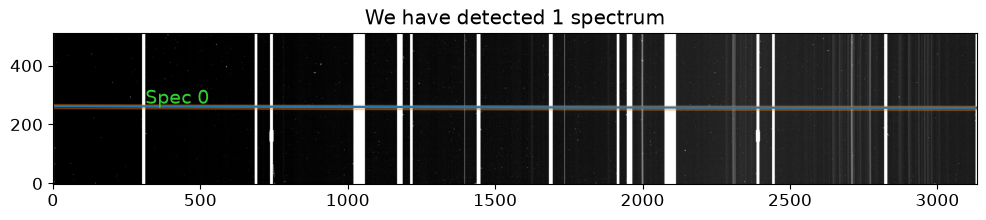

Spectrum 0: median S/N per pixel = 37.7; profile: empirical (FWHM = 4.0 px, order 3 along x); 21 outlier pixel(s) rejected; variance relative to a simple sum = 0.69.
The built-in line lists adopted here (HgI, NeI, ArI, HeI, CuI, CdI, ZnI, KrI, XeI, FeI, ThAr) were taken from PypeIt, which compiled them from NIST and instrument calibrations. Please cite PypeIt and NIST if you use them.
Lamp spectrum 0: 126 lines detected, 69 identified (RMS = 0.254 A = 0.253 px); lambda = 3593.6 to 6734.3 A.
Spectrum 0: 69 lines used, 0 rejected; RMS = 0.2524 A (0.251 px); dispersion = 1.0049 A/px; lambda = 3593.1-6734.2 A.
Please cite the work where this extinction curve was measured:
The CTIO extinction curve was originally distributed with IRAF and comes from the work of Stone & Baldwin (1983 MN 204, 347) plus Baldwin & Stone (1984 MN 206, 241). The first of these papers lists the points from 3200-8370A while the second extended the flux calibration from 6056 to 10870A but the derived extinction curv

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/extraction/extraction.py:2261: UserWarning: Spectrum 0 covers 3593-6734 A, but the sensitivity function is defined only in 3625-6725 A: the spectrum was restricted to this range.
  warnings.warn(f"Spectrum {number} covers {wavelength.min():.0f}-{wavelength.max():.0f} A, but the sensitivity function is defined only in "


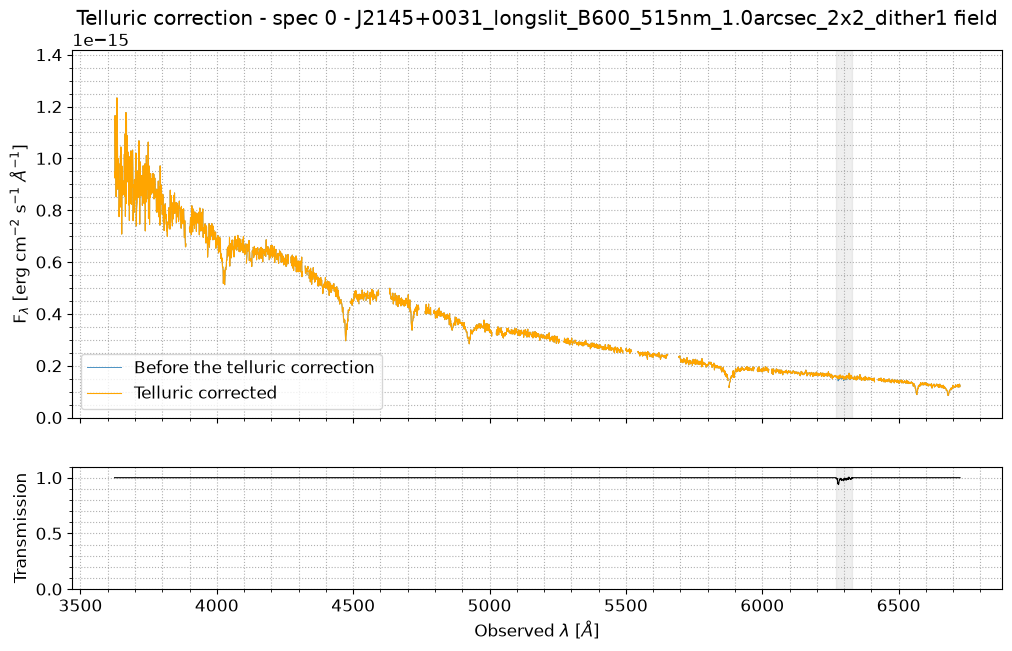

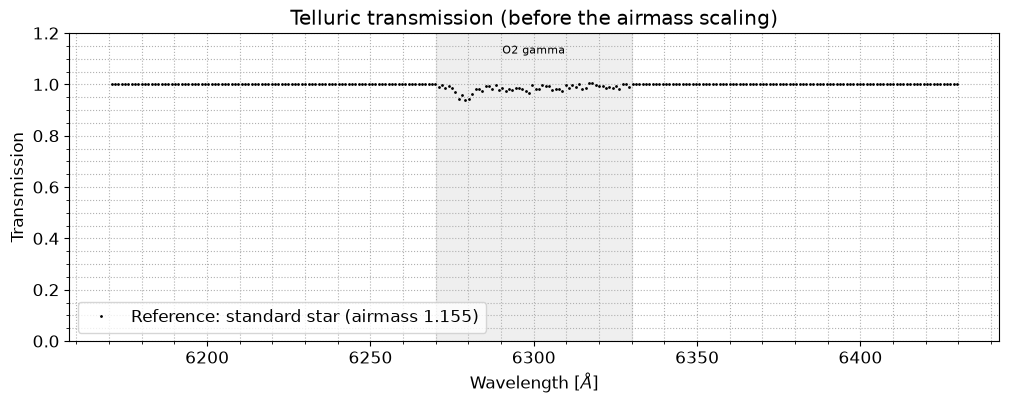

Returning both target and std star images...
Spectrum 0: y = 351.91 at x = 1567; 77 of 97 bins used (x = 15-2988); residual RMS = 0.047 px; spatial FWHM = 4.11 px


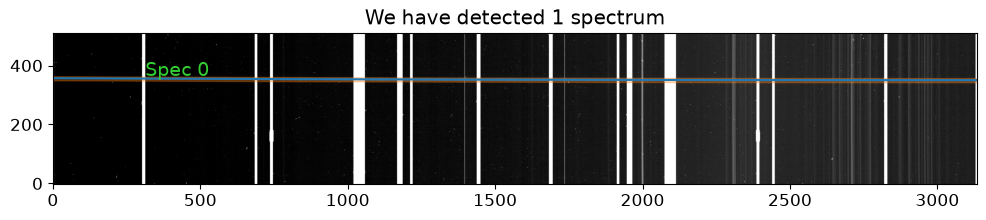

Spectrum 0: median S/N per pixel = 36.5; profile: empirical (FWHM = 4.0 px, order 3 along x); 13 outlier pixel(s) rejected; variance relative to a simple sum = 0.69.
The built-in line lists adopted here (HgI, NeI, ArI, HeI, CuI, CdI, ZnI, KrI, XeI, FeI, ThAr) were taken from PypeIt, which compiled them from NIST and instrument calibrations. Please cite PypeIt and NIST if you use them.
Lamp spectrum 0: 129 lines detected, 74 identified (RMS = 0.257 A = 0.255 px); lambda = 3593.2 to 6734.3 A.
Spectrum 0: 74 lines used, 0 rejected; RMS = 0.2528 A (0.252 px); dispersion = 1.0049 A/px; lambda = 3592.8-6734.1 A.
Please cite the work where this extinction curve was measured:
The CTIO extinction curve was originally distributed with IRAF and comes from the work of Stone & Baldwin (1983 MN 204, 347) plus Baldwin & Stone (1984 MN 206, 241). The first of these papers lists the points from 3200-8370A while the second extended the flux calibration from 6056 to 10870A but the derived extinction curv

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/extraction/extraction.py:2261: UserWarning: Spectrum 0 covers 3593-6734 A, but the sensitivity function is defined only in 3625-6725 A: the spectrum was restricted to this range.
  warnings.warn(f"Spectrum {number} covers {wavelength.min():.0f}-{wavelength.max():.0f} A, but the sensitivity function is defined only in "


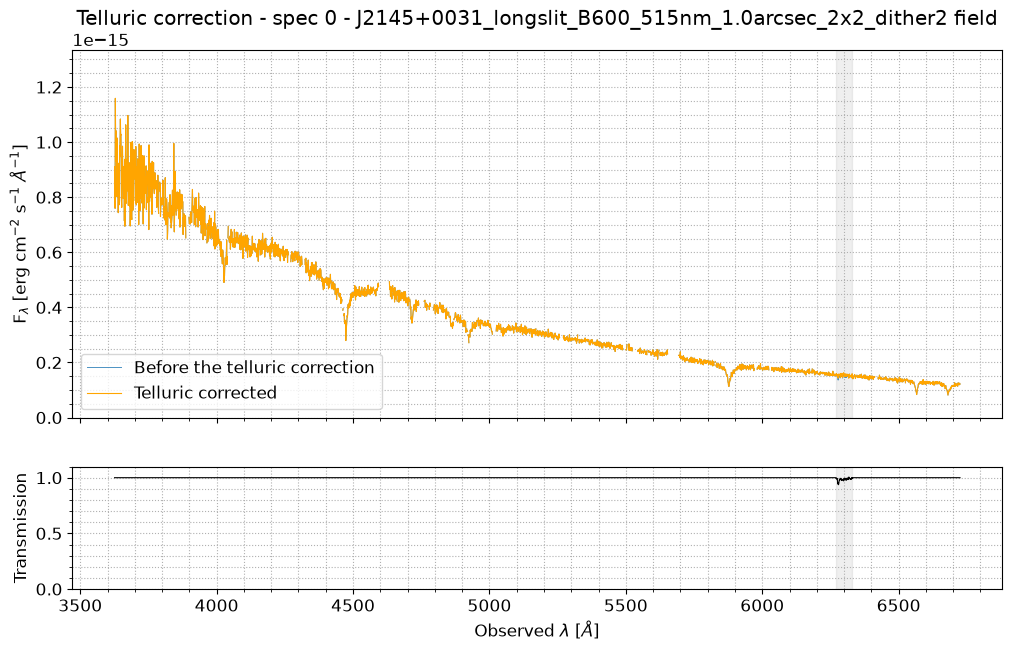

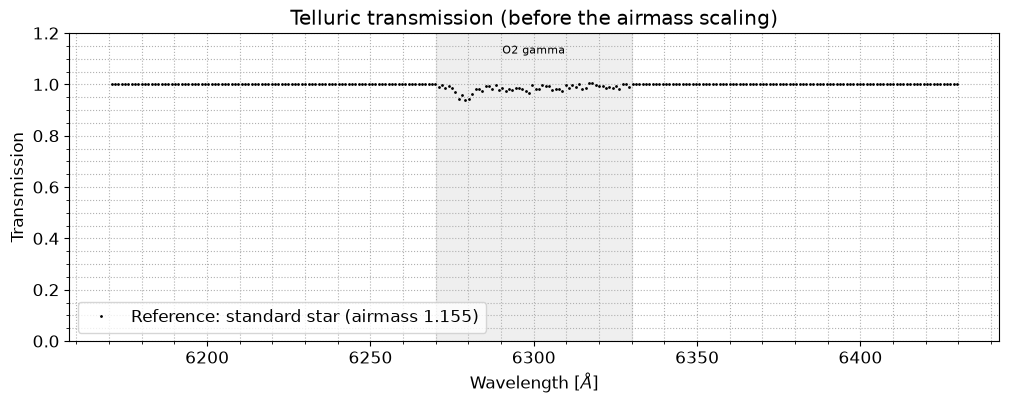

Returning both target and std star images...
Spectrum 0: y = 258.56 at x = 1567; 82 of 97 bins used (x = 15-2988); residual RMS = 0.067 px; spatial FWHM = 4.47 px


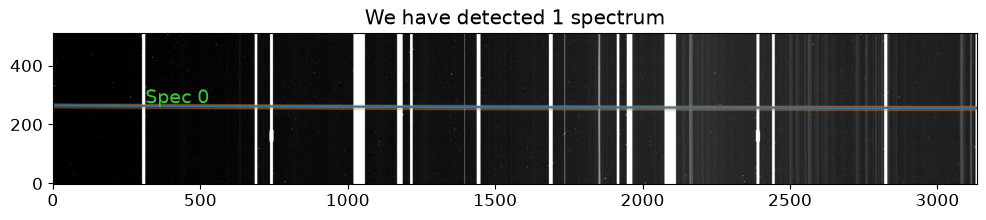

Spectrum 0: median S/N per pixel = 34.8; profile: empirical (FWHM = 4.0 px, order 3 along x); 15 outlier pixel(s) rejected; variance relative to a simple sum = 0.68.
The built-in line lists adopted here (HgI, NeI, ArI, HeI, CuI, CdI, ZnI, KrI, XeI, FeI, ThAr) were taken from PypeIt, which compiled them from NIST and instrument calibrations. Please cite PypeIt and NIST if you use them.
Lamp spectrum 0: 135 lines detected, 69 identified (RMS = 0.193 A = 0.192 px); lambda = 3737.8 to 6883.5 A.
Spectrum 0: 69 lines used, 0 rejected; RMS = 0.1893 A (0.188 px); dispersion = 1.0063 A/px; lambda = 3737.6-6883.3 A.
Please cite the work where this extinction curve was measured:
The CTIO extinction curve was originally distributed with IRAF and comes from the work of Stone & Baldwin (1983 MN 204, 347) plus Baldwin & Stone (1984 MN 206, 241). The first of these papers lists the points from 3200-8370A while the second extended the flux calibration from 6056 to 10870A but the derived extinction curv

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/extraction/extraction.py:2261: UserWarning: Spectrum 0 covers 3738-6883 A, but the sensitivity function is defined only in 3625-6725 A: the spectrum was restricted to this range.
  warnings.warn(f"Spectrum {number} covers {wavelength.min():.0f}-{wavelength.max():.0f} A, but the sensitivity function is defined only in "


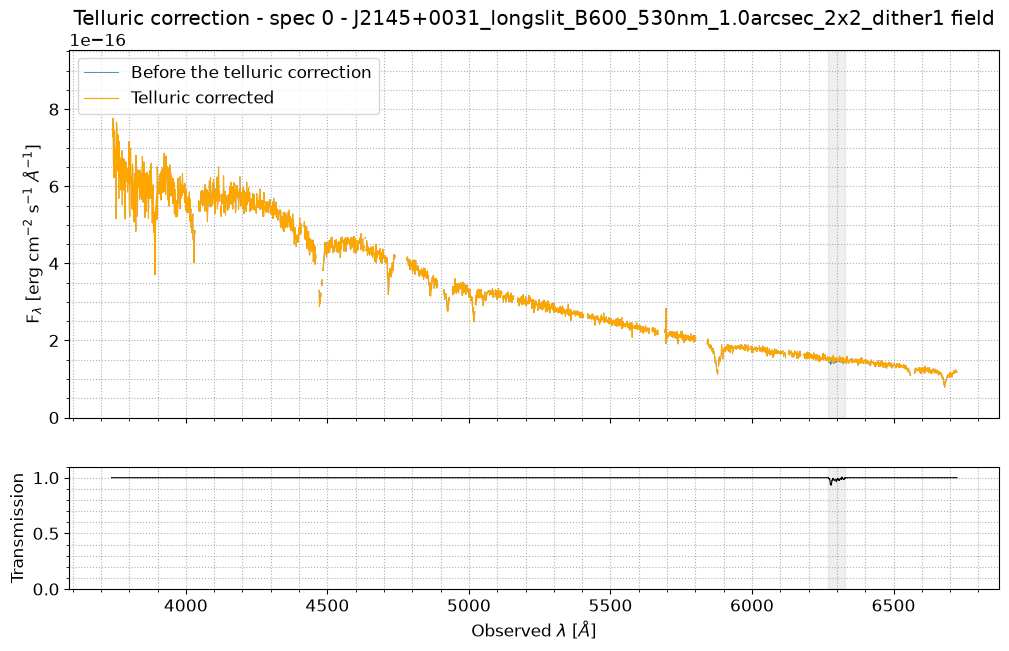

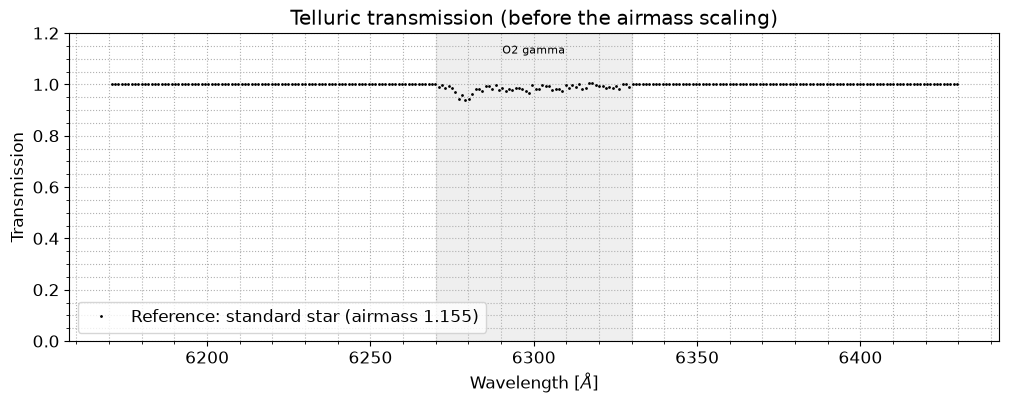

Returning both target and std star images...
Spectrum 0: y = 352.26 at x = 1567; 84 of 97 bins used (x = 15-2988); residual RMS = 0.073 px; spatial FWHM = 4.11 px


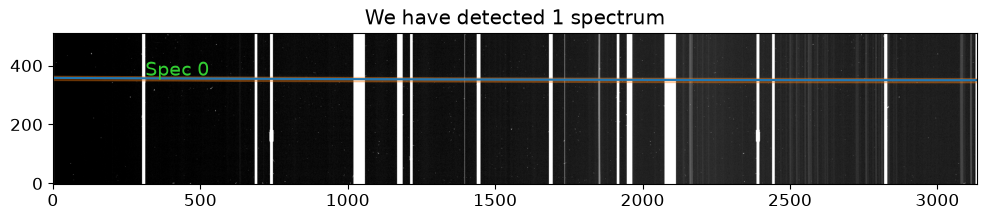

Spectrum 0: median S/N per pixel = 36.2; profile: empirical (FWHM = 4.0 px, order 3 along x); 39 outlier pixel(s) rejected; variance relative to a simple sum = 0.68.
The built-in line lists adopted here (HgI, NeI, ArI, HeI, CuI, CdI, ZnI, KrI, XeI, FeI, ThAr) were taken from PypeIt, which compiled them from NIST and instrument calibrations. Please cite PypeIt and NIST if you use them.
Lamp spectrum 0: 136 lines detected, 66 identified (RMS = 0.174 A = 0.173 px); lambda = 3738.1 to 6883.4 A.
Spectrum 0: 66 lines used, 0 rejected; RMS = 0.1754 A (0.174 px); dispersion = 1.0063 A/px; lambda = 3738.1-6883.4 A.
Please cite the work where this extinction curve was measured:
The CTIO extinction curve was originally distributed with IRAF and comes from the work of Stone & Baldwin (1983 MN 204, 347) plus Baldwin & Stone (1984 MN 206, 241). The first of these papers lists the points from 3200-8370A while the second extended the flux calibration from 6056 to 10870A but the derived extinction curv

/home/raniere/Documentos/easyspec/testes/Claude/easyspec/extraction/extraction.py:2261: UserWarning: Spectrum 0 covers 3738-6883 A, but the sensitivity function is defined only in 3625-6725 A: the spectrum was restricted to this range.
  warnings.warn(f"Spectrum {number} covers {wavelength.min():.0f}-{wavelength.max():.0f} A, but the sensitivity function is defined only in "


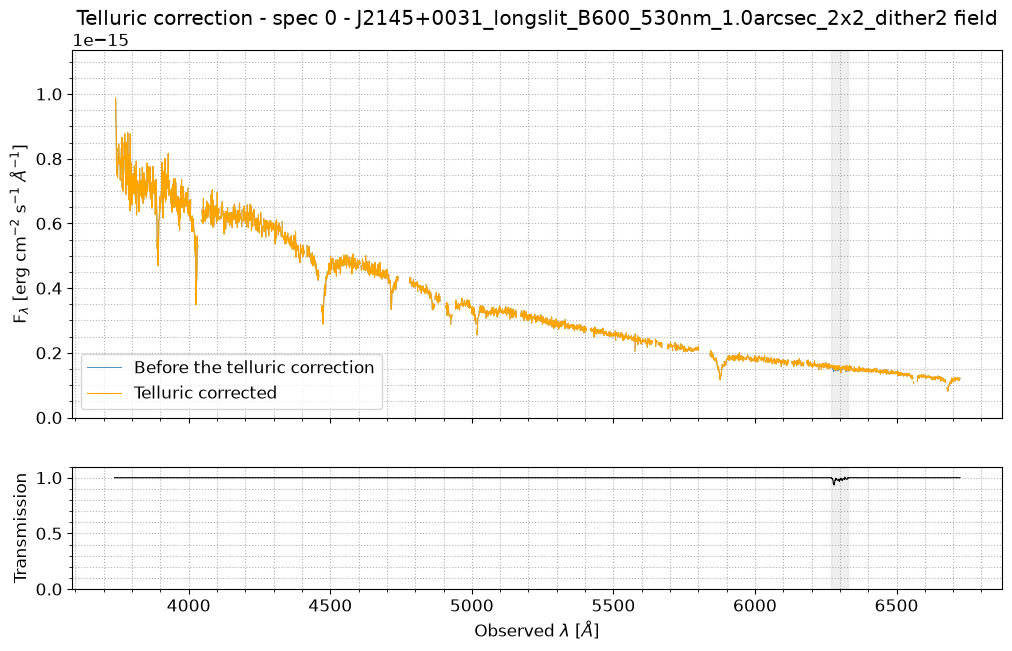

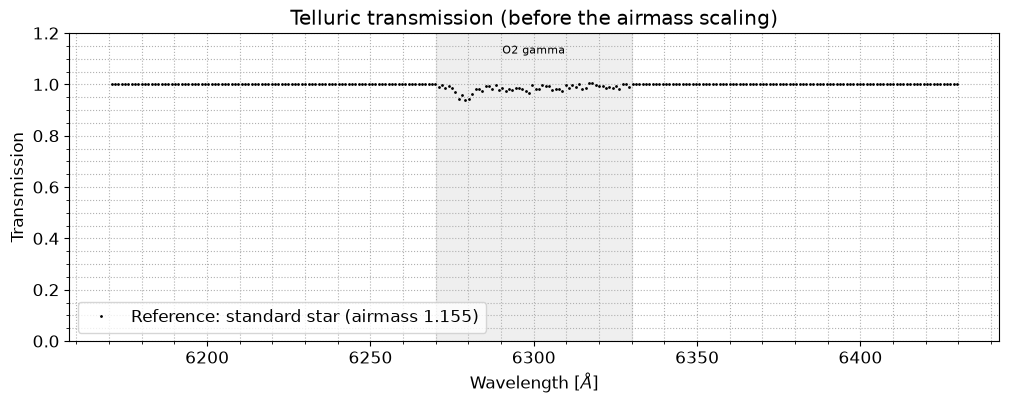

[PosixPath('Gemini_results/J2145+0031_longslit_B600_515nm_1.0arcsec_2x2_dither1_spec_0_telluric.dat'), PosixPath('Gemini_results/J2145+0031_longslit_B600_515nm_1.0arcsec_2x2_dither2_spec_0_telluric.dat'), PosixPath('Gemini_results/J2145+0031_longslit_B600_530nm_1.0arcsec_2x2_dither1_spec_0_telluric.dat'), PosixPath('Gemini_results/J2145+0031_longslit_B600_530nm_1.0arcsec_2x2_dither2_spec_0_telluric.dat')]


In [10]:
spectrum_files = []
for setup in setups:
    for dither in dithers:
        spectrum_file = calibrate_dither(setup, dither, sensitivity_function, spec_atm_corrected_std, wavelengths_std, plot=True)
        spectrum_files.append(spectrum_file)

print(spectrum_files)

Notice that the spectra of 530 nm start and end ~150 A redder than those of 515 nm. The flux calibration is valid only where the sensitivity function is defined (3625-6725 A, the range of the standard star, observed with 515 nm), so the red end of the 530 nm spectra is cut.

## Step 5. Stacking the 4 spectra

Finally, `analysis.stack_calib_spectra()` resamples the 4 spectra onto a common wavelength grid and combines them, with their uncertainties and data quality masks:

- `method="weighted"`: inverse-variance weighted mean (the 4 exposures have the same exposure time, but not the same signal-to-noise ratio);
- `normalize="reference"`: each spectrum is scaled to the one with the highest signal-to-noise ratio, which corrects small differences of slit losses and transparency between the exposures;
- the CCD gaps of one setup are filled by the other setup; `min_spectra=1` keeps the pixels covered by a single spectrum.

Stacked 4 spectra (weighted) onto 3086 pixels of 1.005 A (3625.1-6724.9 A); 3046 pixels with data.
  J2145+0031_longslit_B600_515nm_1.0arcsec_2x2_dither1_spec_0_telluric: reference, chi2_red around the mean = 1.40
  J2145+0031_longslit_B600_515nm_1.0arcsec_2x2_dither2_spec_0_telluric: scale factor 1.026, chi2_red around the mean = 1.30
  J2145+0031_longslit_B600_530nm_1.0arcsec_2x2_dither1_spec_0_telluric: scale factor 1.035, chi2_red around the mean = 2.17
  J2145+0031_longslit_B600_530nm_1.0arcsec_2x2_dither2_spec_0_telluric: scale factor 1.004, chi2_red around the mean = 1.19


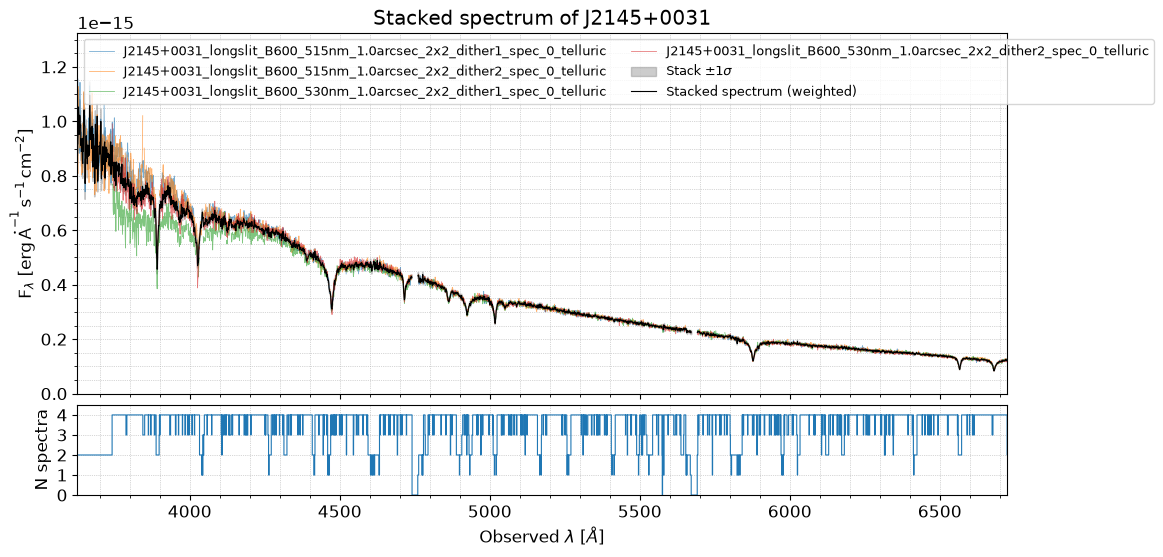

Stacked spectrum saved in Gemini_results/J2145+0031_stacked_weighted.dat


In [11]:
stack = analysis()
wavelengths_stacked, flux_stacked, flux_stacked_error = stack.stack_calib_spectra(spectrum_files, method="weighted",
                                                                                 target_name=target_name,
                                                                                 output_dir=output_directory,
                                                                                 normalize="reference", reference="best",
                                                                                 min_spectra=1, save_file=True,
                                                                                 file_format="dat", return_errors=True,
                                                                                 plot=True, plot_overlayed_spectra=True)

In the lower panel, the number of spectra in each pixel: 4 in most of the spectrum, fewer at the CCD gaps of each setup and at the bad columns. The blue end (below ~3740 A) is covered only by the two spectra of 515 nm. The spectrum shows the He I absorption lines (e.g. 4026, 4471, 4922, 5016, 5876 and 6678 A).

That's it! The stacked spectrum is saved in `Gemini_results`, and it can be analysed with the `analysis()` class (e.g. `find_lines()` and `fit_lines()`), as in the other tutorials.